# 07 — ResNet-50 320×320 dan pembaruan ensemble
Eksperimen sebelumnya menghasilkan accuracy validasi **87,6310%** dan macro-F1 **0,875485** melalui gabungan EfficientNet 224/320 dan ResNet 224. Skor leaderboard submission tersebut belum dilaporkan ketika tahap ini dimulai. Skor leaderboard terakhir yang diketahui, **0,86491**, berasal dari ensemble dua EfficientNet.

Hipotesis: resolusi ResNet yang lebih tinggi mempertahankan lebih banyak rincian halaman dan dapat membantu kelas scientific_report, presentation, serta form. Ini hipotesis yang diuji pada validasi, bukan jaminan peningkatan.

In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/resnet_highres'
SELECTED = ROOT / 'reports/resnet_highres_selection'
display(pd.read_json(ROOT / 'reports/leaderboard_history.json'))
display(pd.read_csv(ROOT / 'reports/diversity_selection/classification_report.csv', index_col=0).iloc[:16].sort_values('f1-score').head())

,reported_on,run_name,submission,submission_sha256,score,score_source,leaderboard_partition,metric_name
0,2026-10-27,baseline_cnn,submissions/submission_baseline.csv,5fd9913aedf081fdb66e9823eb28e36e6146162113f3d1...,0.67294,Reported by user in chat,unspecified,unverified
1,2026-10-28,efficientnet_improved,submissions/submission_improved.csv,2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80...,0.85236,Reported by user in chat,unspecified,unverified
2,2026-10-28,highres_selection,submissions/submission_highres_selected.csv,9a2231e16ba635ae4f99aa8f74fe8ed5efd46853e856fc...,0.86491,Reported by user in chat,unspecified,unverified


,precision,recall,f1-score,support
scientific_report,0.730583,0.735941,0.733252,409.0
presentation,0.722749,0.772152,0.746634,395.0
form,0.769437,0.769437,0.769437,373.0
questionnaire,0.845361,0.854167,0.849741,384.0
budget,0.854545,0.845758,0.850129,389.0


## Melanjutkan checkpoint tanpa mengubah split
Checkpoint sumber berasal dari epoch terbaik ResNet 224 pada training split yang sama. Pipeline memeriksa fingerprint metadata, arsitektur, class mapping, dan ID validasi sebelum memuat bobot. Cache 320 berasal dari TIFF asli dengan letterbox dan padding putih; bukan upscaling cache 224.

Optimizer AdamW dimulai ulang dengan LR 0,00003, cosine schedule 6 epoch, batch 24, weight decay 0,01, label smoothing 0,05, dan patience 3. Augmentasi tetap sama: kontras ringan dan affine kecil; tanpa flip. Resolusi serta jadwal fine-tuning berubah bersama sehingga kontribusinya belum dipisahkan.

Reproduksi: `python -m scripts.train --config configs/resnet_highres.json --device cuda`. Semua layer dilatih menggunakan PyTorch; input hanya piksel.

In [2]:
display(json.loads((ROOT / 'configs/resnet_highres.json').read_text()))
display(json.loads((RUN / 'run.json').read_text()))
display(pd.read_csv(RUN / 'history.csv'))
display(Markdown((RUN / 'interpretation.md').read_text(encoding='utf-8')))

{'run_name': 'resnet_highres',
 'model': 'resnet50',
 'pretrained': False,
 'init_checkpoint': 'checkpoint/resnet_diversity/best.pt',
 'image_size': 320,
 'epochs': 6,
 'batch_size': 24,
 'learning_rate': 3e-05,
 'weight_decay': 0.01,
 'label_smoothing': 0.05,
 'patience': 3,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 2,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy',
 'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}}

{'config': {'run_name': 'resnet_highres',
  'model': 'resnet50',
  'pretrained': False,
  'init_checkpoint': 'checkpoint/resnet_diversity/best.pt',
  'image_size': 320,
  'epochs': 6,
  'batch_size': 24,
  'learning_rate': 3e-05,
  'weight_decay': 0.01,
  'label_smoothing': 0.05,
  'patience': 3,
  'seed': 42,
  'validation_fraction': 0.2,
  'workers': 2,
  'threads': 4,
  'amp': True,
  'selection_metric': 'accuracy',
  'geometry': {'degrees': 1.5, 'translate': 0.015, 'scale': 0.03}},
 'device': 'cuda',
 'versions': {'torch': '2.11.0+cu128',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.7',
  'torchvision': '0.26.0+cu128'},
 'initialization': {'path': 'checkpoint/resnet_diversity/best.pt',
  'sha256': '6c74f241f766e61dbb2eb6e27a812b0cd967d9573848c0cc34176c6791cd1858',
  'source_epoch': 9,
  'optimizer_reset': True},
 'device_name': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'train_rows': 25607,
 'validation_rows': 6395,
 'm

,epoch,train_loss,val_loss,accuracy,macro_f1,learning_rate,seconds
0,1,0.568966,0.542188,0.856294,0.854859,0.000030,312.313140
1,2,0.446523,0.537356,0.865207,0.864175,0.000028,252.595750
2,3,0.401015,0.531907,0.866145,0.864731,0.000023,251.583509
3,4,0.374993,0.545519,0.863643,0.862642,0.000015,251.579749
4,5,0.361807,0.542153,0.864269,0.863259,0.000008,246.604523
5,6,0.355658,0.539443,0.862080,0.860787,0.000002,246.662549


### Eksperimen `resnet_highres`

| Metrik | Hasil |
| --- | ---: |
| Accuracy validasi | 86.6145% |
| Macro-F1 validasi | 0.864731 |
| Majority-class baseline accuracy | 6.5676% |
| Halaman training / validasi | 25,607 / 6,395 |
| Epoch terbaik / epoch dijalankan | 3 / 6 |
| Waktu loop training + validasi | 26.0 menit |
| Perangkat | cuda |
| Skor leaderboard | Belum tersedia |

Kelas dengan F1 tertinggi: `email` (0.975), `handwritten` (0.936), `file_folder` (0.931).
Kelas dengan F1 terendah: `scientific_report` (0.714), `presentation` (0.729), `form` (0.735).

Kesalahan terbanyak (aktual → prediksi): `scientific_report` → `presentation` (34 halaman); `presentation` → `scientific_report` (29 halaman); `form` → `invoice` (22 halaman).

Accuracy validasi per epoch berkisar 85.63%–86.61%. Checkpoint dipilih berdasarkan metrik holdout pada konfigurasi. Training loss memakai label smoothing sedangkan validation loss tidak, sehingga nilai absolut keduanya tidak sepenuhnya sebanding.

Hasil ini mengukur satu holdout dengan pemisahan duplikat persis. Holdout juga dipakai untuk memilih checkpoint, sehingga skor dapat optimistis setelah tuning. Skor tersebut bukan public/private leaderboard.

Model `resnet50` menggunakan resolusi 320×320. Kemiripan layout adalah hipotesis penyebab kesalahan, bukan kesimpulan kausal dari confusion matrix. Periksa kelas lemah dan contoh halaman sebelum menentukan eksperimen berikutnya.

Artefak: [metrics](metrics.json), [history](history.csv), [split](split.csv), dan [interpretasi lengkap](interpretation.md).

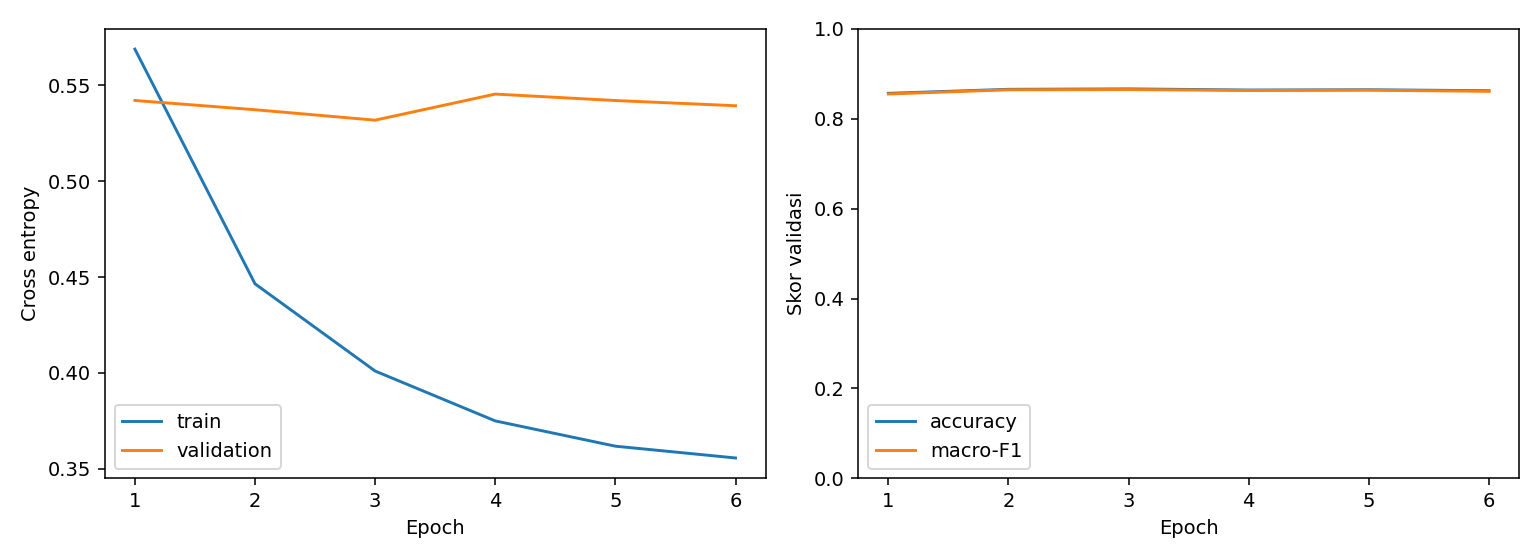

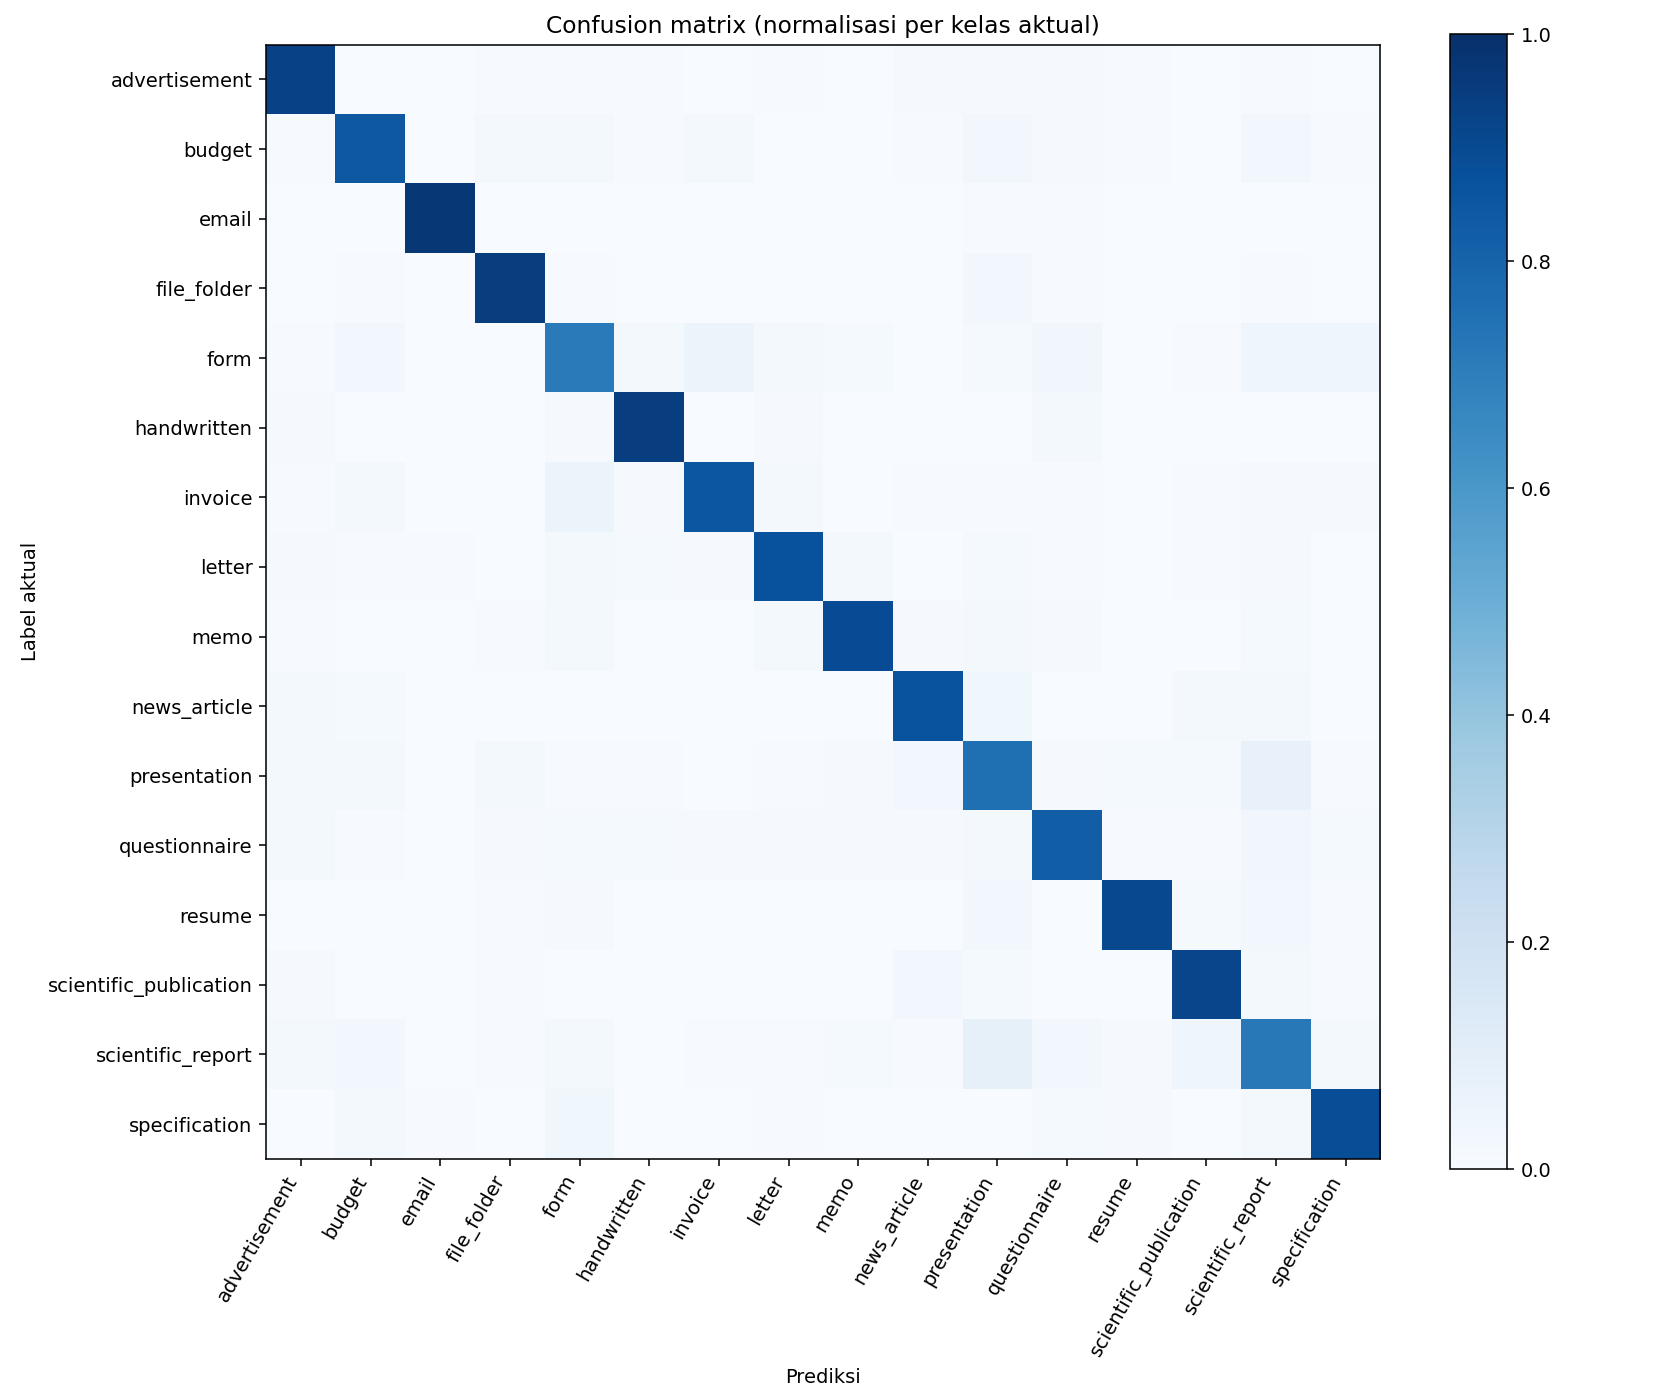

,class_name,baseline_f1,candidate_f1,delta_f1
15,specification,0.897574,0.882273,-0.015301
4,form,0.749665,0.734807,-0.014859
10,presentation,0.736970,0.729498,-0.007472
8,memo,0.915842,0.909530,-0.006312
2,email,0.980392,0.975098,-0.005294
11,questionnaire,0.834420,0.829396,-0.005023
9,news_article,0.874832,0.871465,-0.003366
5,handwritten,0.938776,0.936455,-0.002321
12,resume,0.922364,0.922722,0.000358
13,scientific_publication,0.903756,0.905660,0.001905


In [3]:
display(Image(filename=str(RUN / 'learning_curves.png')))
display(Image(filename=str(RUN / 'confusion_matrix.png')))
display(pd.read_csv(RUN / 'class_comparison.csv').sort_values('delta_f1'))

## Empat kandidat ditetapkan sebelum training
Urutan komponen: EfficientNet 224, EfficientNet 320, ResNet 224, ResNet 320. Kandidat pertama adalah ensemble sebelumnya dengan bobot [0,25; 0,25; 0,50; 0]. Pembandingnya adalah ResNet 320 tunggal, penggantian komponen ResNet 224 dengan ResNet 320, dan rata-rata empat model. Semua bobot tersedia pada konfigurasi di bawah.

Pilih accuracy validasi tertinggi; seri memilih kandidat paling awal. Tidak ada tuning bobot per kelas, label test, atau lookup gambar duplikat. Pemilihan checkpoint dan empat kandidat ini menambah penggunaan holdout untuk tuning, sehingga skor belum menjadi estimasi independen.

In [4]:
selection = json.loads((SELECTED / 'selection.json').read_text())
display(json.loads((ROOT / 'configs/resnet_highres_selection.json').read_text()))
display(pd.read_csv(SELECTED / 'candidates.csv'))
display(Markdown((SELECTED / 'interpretation.md').read_text(encoding='utf-8')))
display(pd.read_csv(SELECTED / 'class_comparison.csv').sort_values('delta_f1'))
display(pd.read_csv(SELECTED / 'confident_errors.csv').head(10))

{'experiment': 'resnet_highres_selection',
 'runs': ['efficientnet_improved',
  'efficientnet_highres',
  'resnet_diversity',
  'resnet_highres'],
 'candidates': [{'variant': 'previous_diverse_blend',
   'weights': [0.25, 0.25, 0.5, 0.0]},
  {'variant': 'resnet_highres_single', 'weights': [0.0, 0.0, 0.0, 1.0]},
  {'variant': 'replace_resnet_224', 'weights': [0.25, 0.25, 0.0, 0.5]},
  {'variant': 'four_model_blend', 'weights': [0.25, 0.25, 0.25, 0.25]}],
 'selection_rule': 'Highest holdout accuracy; ties prefer the first listed candidate',
 'submission': 'submissions/submission_resnet_highres_selected.csv'}

,variant,weights,accuracy,macro_f1
0,previous_diverse_blend,"[0.25, 0.25, 0.5, 0.0]",0.876310,0.875485
1,resnet_highres_single,"[0.0, 0.0, 0.0, 1.0]",0.866145,0.864731
2,replace_resnet_224,"[0.25, 0.25, 0.0, 0.5]",0.880688,0.879886
3,four_model_blend,"[0.25, 0.25, 0.25, 0.25]",0.882252,0.881401


# Pemilihan resnet_highres_selection

Kandidat terpilih: **four_model_blend**, bobot [0.25, 0.25, 0.25, 0.25].

| Kandidat | Accuracy validasi | Macro-F1 |
| --- | ---: | ---: |
| previous_diverse_blend | 87.6310% | 0.875485 |
| resnet_highres_single | 86.6145% | 0.864731 |
| replace_resnet_224 | 88.0688% | 0.879886 |
| four_model_blend | 88.2252% | 0.881401 |

Perubahan terhadap kandidat pertama: +0.59 poin persentase accuracy pada 6,395 halaman validasi yang sama.
Memperbaiki 78 kesalahan dan menambah 40 kesalahan. F1 meningkat pada 13 dari 16 kelas.

Kelas terlemah: scientific_report (0.749), presentation (0.754), form (0.767).

Manfaat komponen baru dinilai melalui hasil kandidat tunggal dan gabungan. Eksperimen ini tidak memisahkan efek arsitektur, resolusi, inisialisasi, dan jadwal training secara kausal.

Holdout yang sama sudah digunakan untuk memilih checkpoint dan kandidat. Tidak ada evaluasi CV independen setelah tuning. Tidak ada label test atau lookup duplikat test yang dipakai. Skor leaderboard baru harus dicatat setelah submission.

File: `submissions/submission_resnet_highres_selected.csv` (7,994 baris). Hash dan rincian komponen tersedia di `selection.json`.

,class_name,previous_f1,selected_f1,delta_f1
15,specification,0.921409,0.916442,-0.004967
4,form,0.769437,0.766578,-0.002859
2,email,0.980341,0.977661,-0.002680
11,questionnaire,0.849741,0.851948,0.002207
12,resume,0.924485,0.928571,0.004086
5,handwritten,0.941309,0.946067,0.004758
8,memo,0.924969,0.930403,0.005434
6,invoice,0.863388,0.868966,0.005578
13,scientific_publication,0.915976,0.922894,0.006918
10,presentation,0.746634,0.754017,0.007383


,id,filename,class_name,label,prediction,predicted_class,confidence
0,train_25513,train/invoice/508729058.tif,invoice,6,4,form,0.972297
1,train_14808,train/presentation/2502337510_7520.tif,presentation,10,14,scientific_report,0.970478
2,train_05863,train/scientific_report/2057124602_4603.tif,scientific_report,14,15,specification,0.970244
3,train_17516,train/scientific_report/2082647017_7026.tif,scientific_report,14,10,presentation,0.969425
4,train_10006,train/presentation/2028987355_2028987357.tif,presentation,10,14,scientific_report,0.968279
5,train_16971,train/handwritten/509132718+-2718.tif,handwritten,5,0,advertisement,0.968148
6,train_03399,train/scientific_report/81560070_0086.tif,scientific_report,14,10,presentation,0.966915
7,train_17566,train/scientific_report/2053453117.tif,scientific_report,14,15,specification,0.966577
8,train_11150,train/memo/94158557.tif,memo,8,4,form,0.966465
9,train_29353,train/resume/2025684886.tif,resume,12,10,presentation,0.963810


## Validasi submission
File terpilih tetap mengikuti urutan ID sample submission. Hash checkpoint, arsip validasi, konfigurasi kandidat, dan submission dicatat pada selection.json. Arsip validasi EfficientNet lama belum menyimpan hash checkpoint; konsistensinya diperiksa melalui prediksi tercatat. Arsip kedua ResNet memiliki hash checkpoint.

Skor holdout dan leaderboard dibedakan. Submission terdahulu dipertahankan agar perubahan hasil bisa ditelusuri.

In [5]:
from scripts.predict import validate_submission
from scripts.preprocess import read_metadata, data_directory
_, test, sample = read_metadata(data_directory())
path = ROOT / selection['submission']
submission = pd.read_csv(path)
validate_submission(submission, sample)
assert len(submission) == len(test)
assert hashlib.sha256(path.read_bytes()).hexdigest() == selection['submission_sha256']
previous = json.loads((ROOT / 'reports/diversity_selection/selection.json').read_text())
assert hashlib.sha256((ROOT / previous['submission']).read_bytes()).hexdigest() == previous['submission_sha256']
for row in json.loads((ROOT / 'reports/leaderboard_history.json').read_text()):
    assert hashlib.sha256((ROOT / row['submission']).read_bytes()).hexdigest() == row['submission_sha256']
print(f'Validated {len(submission)} rows; variant={selection["selected"]["variant"]}')
display(submission.head())

Validated 7994 rows; variant=four_model_blend


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
